# Tracking a High-Speed Train under Biased Process Dynamics

## Step I. Filtering the data

In [3]:
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

In [4]:
# GPS measurements of the train position, measured every 2 seconds
data_dir = Path("data")
measured_trajectory_train = np.loadtxt(data_dir / "GPS.txt")

SIZE = measured_trajectory_train.size
T = 2

VARIANCE_A = 0.2**2
VARIANCE_ETA = 20**2
SIGMA_ETA = np.sqrt(VARIANCE_ETA)

steps = np.arange(SIZE * T, step = T)

In [5]:
# state-space model of the train (from assignment 6)
PHI = np.array([[1, T],
                [0, 1]])

G = np.array([[T**2 / 2],
              [T]])

H = np.array([[1, 0]])

Q = G @ G.T * VARIANCE_A
R = np.array([[VARIANCE_ETA]])

# initial conditions
X_0_0 = np.array([[2],
                  [0]])
P_0_0 = np.array([[100, 0],
                  [0, 100]])

In [18]:
# Kalman filter (from assignment 6) with an optional bias q of the state noise in the prediction step
# also returns the residuals r_i = z_i - H X_{i,i-1} and their variance S_i = H P_{i,i-1} H^T + R
def kalman_filter(measurements, phi, g, h, q, r, x_0_0, p_0_0, q_bias=0):
    size = measurements.size

    x_pred = np.zeros((size, 2, 1))
    p_pred = np.zeros((size, 2, 2))
    x_filt = np.zeros((size, 2, 1))
    p_filt = np.zeros((size, 2, 2))
    k = np.zeros((size, 2, 1))
    residuals = np.zeros(size)
    s = np.zeros(size)

    identity = np.eye(2)
    x_prev = x_0_0
    p_prev = p_0_0

    for i in range(size):
        # prediction
        x_pred[i] = phi @ x_prev + g * q_bias
        p_pred[i] = phi @ p_prev @ phi.T + q

        # filtration
        s[i] = (h @ p_pred[i] @ h.T + r)[0, 0]
        k[i] = p_pred[i] @ h.T / s[i]
        residuals[i] = measurements[i] - (h @ x_pred[i])[0][0]
        x_filt[i] = x_pred[i] + k[i] * residuals[i]
        p_filt[i] = (identity - k[i] @ h) @ p_pred[i]

        x_prev = x_filt[i]
        p_prev = p_filt[i]

    return x_pred, p_pred, x_filt, p_filt, k, residuals, s

In [19]:
x_pred, P_pred, x_filt, P_filt, K, residuals, S = kalman_filter(measured_trajectory_train, PHI, G, H, Q, R, X_0_0, P_0_0)

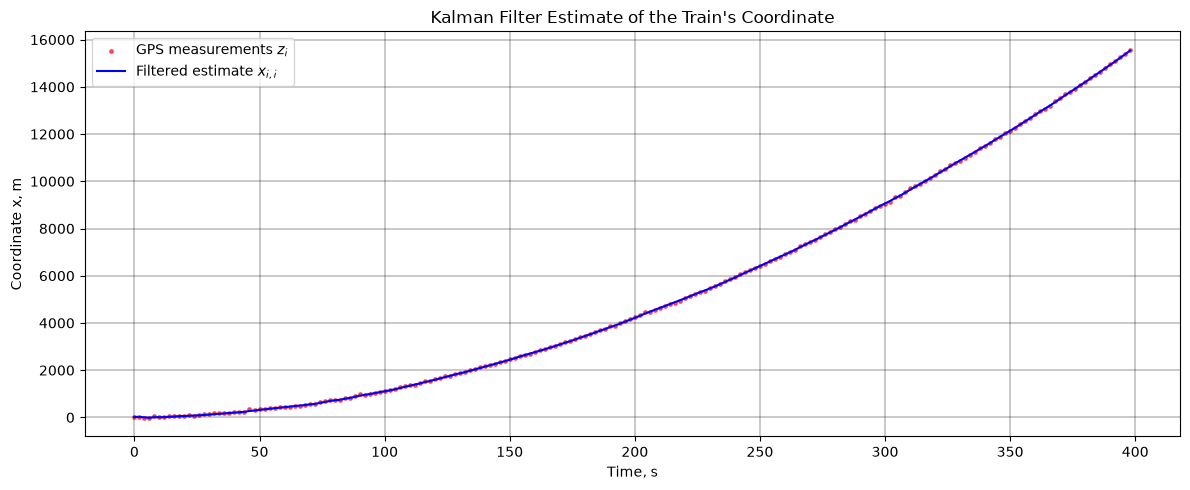

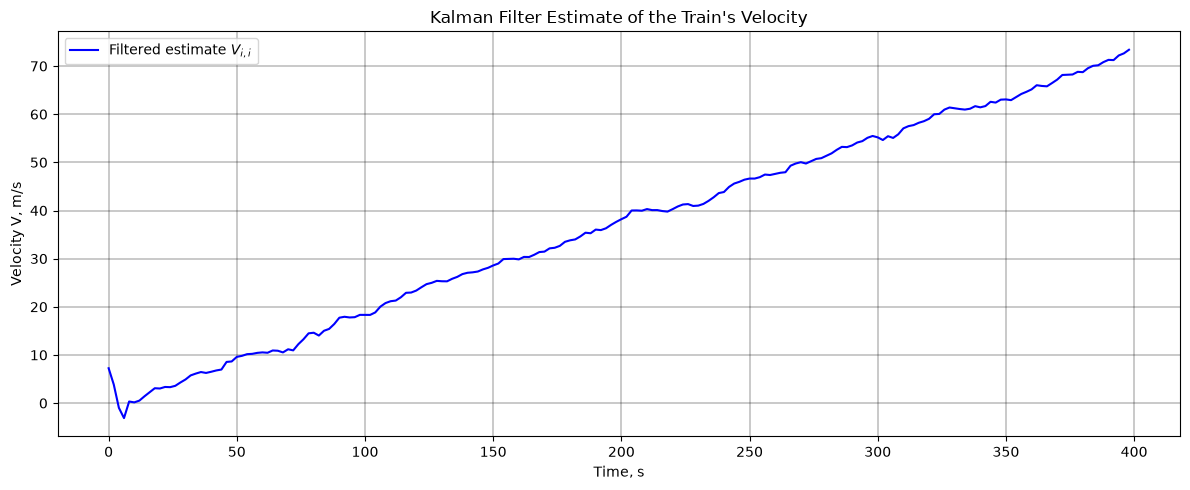

In [22]:
# plot the GPS measurements and the filtered estimates of the coordinate and the velocity
def plot_filter_results(measured_traj, x_filt, title_coordinate, title_velocity):
    fig_coordinate, ax_coordinate = plt.subplots(figsize=(12, 5))
    ax_coordinate.scatter(steps, measured_traj, color="red", s=6, alpha=0.6, label="GPS measurements $z_i$")
    ax_coordinate.plot(steps, x_filt[:, 0, 0], color="blue", linewidth=1.5, label="Filtered estimate $x_{i,i}$")
    ax_coordinate.set_title(title_coordinate)
    ax_coordinate.set_xlabel("Time, s")
    ax_coordinate.set_ylabel("Coordinate x, m")
    ax_coordinate.grid(True, color="black", linewidth=0.3)
    ax_coordinate.legend(frameon=True)
    fig_coordinate.tight_layout()
    plt.show()

    fig_velocity, ax_velocity = plt.subplots(figsize=(12, 5))
    ax_velocity.plot(steps, x_filt[:, 1, 0], color="blue", linewidth=1.5, label="Filtered estimate $V_{i,i}$")
    ax_velocity.set_title(title_velocity)
    ax_velocity.set_xlabel("Time, s")
    ax_velocity.set_ylabel("Velocity V, m/s")
    ax_velocity.grid(True, color="black", linewidth=0.3)
    ax_velocity.legend(frameon=True)
    fig_velocity.tight_layout()
    plt.show()

plot_filter_results(
    measured_trajectory_train,
    x_filt,
    "Kalman Filter Estimate of the Train's Coordinate",
    "Kalman Filter Estimate of the Train's Velocity",
)

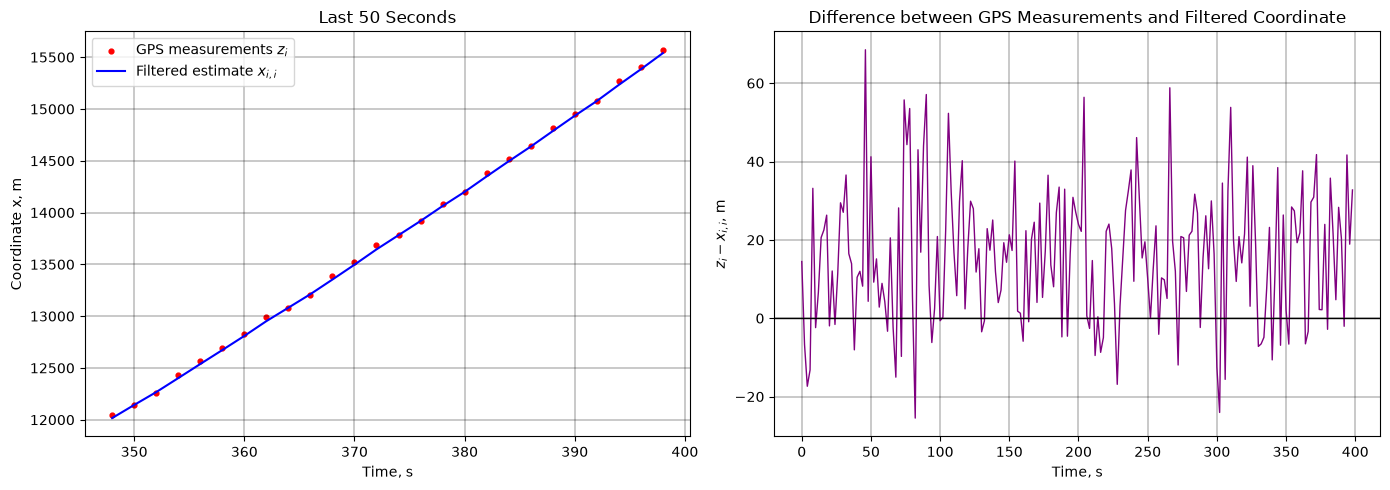

In [9]:
# zoom in on the last 50 seconds and the difference between the filtered estimate and the measurements
zoom = steps >= steps[-1] - 50

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(steps[zoom], measured_trajectory_train[zoom], color="red", s=12, label="GPS measurements $z_i$")
axes[0].plot(steps[zoom], x_filt[zoom, 0, 0], color="blue", linewidth=1.5, label="Filtered estimate $x_{i,i}$")
axes[0].set_title("Last 50 Seconds")
axes[0].set_xlabel("Time, s")
axes[0].set_ylabel("Coordinate x, m")
axes[0].grid(True, color="black", linewidth=0.3)
axes[0].legend(frameon=True)

axes[1].plot(steps, measured_trajectory_train - x_filt[:, 0, 0], color="purple", linewidth=1)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Difference between GPS Measurements and Filtered Coordinate")
axes[1].set_xlabel("Time, s")
axes[1].set_ylabel("$z_i - x_{i,i}$, m")
axes[1].grid(True, color="black", linewidth=0.3)
fig.tight_layout()
plt.show()

## Step II. Checking residuals for signs of bias

In [10]:
# fraction of residuals inside the corridor +-sqrt(S_i)
def get_inside_fraction(residuals, s):
    return np.sum(np.abs(residuals) <= np.sqrt(s)) / residuals.size

print(f"Mean of residuals: {np.mean(residuals):.2f} m")
print(f"Residuals inside ±sqrt(S_i): {100 * get_inside_fraction(residuals, S):.1f}%")

Mean of residuals: 20.79 m
Residuals inside ±sqrt(S_i): 51.5%


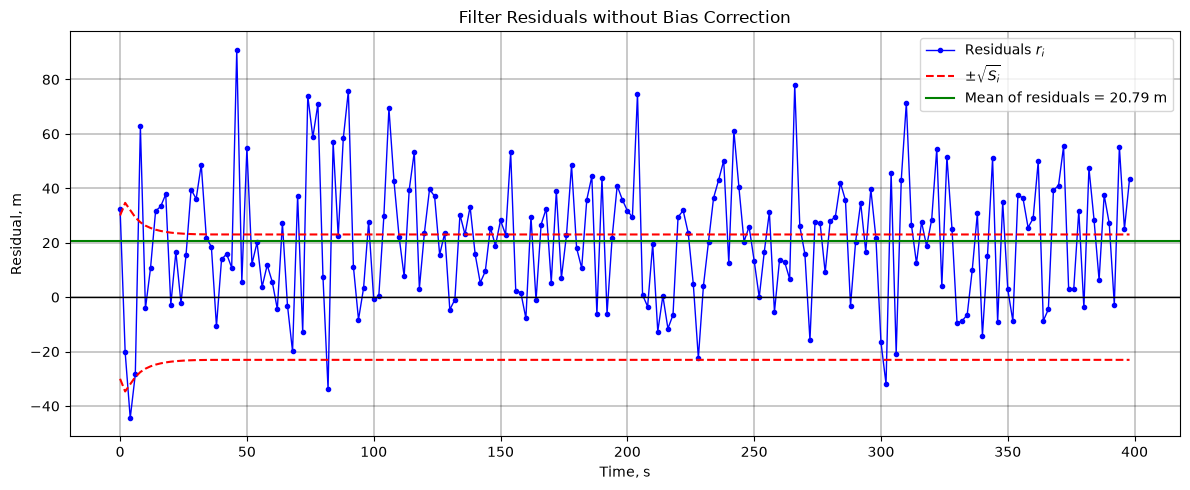

In [21]:
# plot the residuals together with the limits +-sqrt(S_i)
def plot_residuals(residuals, s, title):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, residuals, color="blue", linewidth=1, marker="o", markersize=3, label="Residuals $r_i$")
    ax.plot(steps, np.sqrt(s), color="red", linestyle="--", linewidth=1.5, label="$\\pm\\sqrt{S_i}$")
    ax.plot(steps, -np.sqrt(s), color="red", linestyle="--", linewidth=1.5)
    ax.axhline(np.mean(residuals), color="green", linewidth=1.5, label=f"Mean of residuals = {np.mean(residuals):.2f} m")
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Residual, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

plot_residuals(residuals, S, "Filter Residuals without Bias Correction")

## Step III. Correcting the bias

Mean of residuals: -1.15 m (without correction: 20.79 m)
Residuals inside ±sqrt(S_i): 66.5% (without correction: 51.5%)


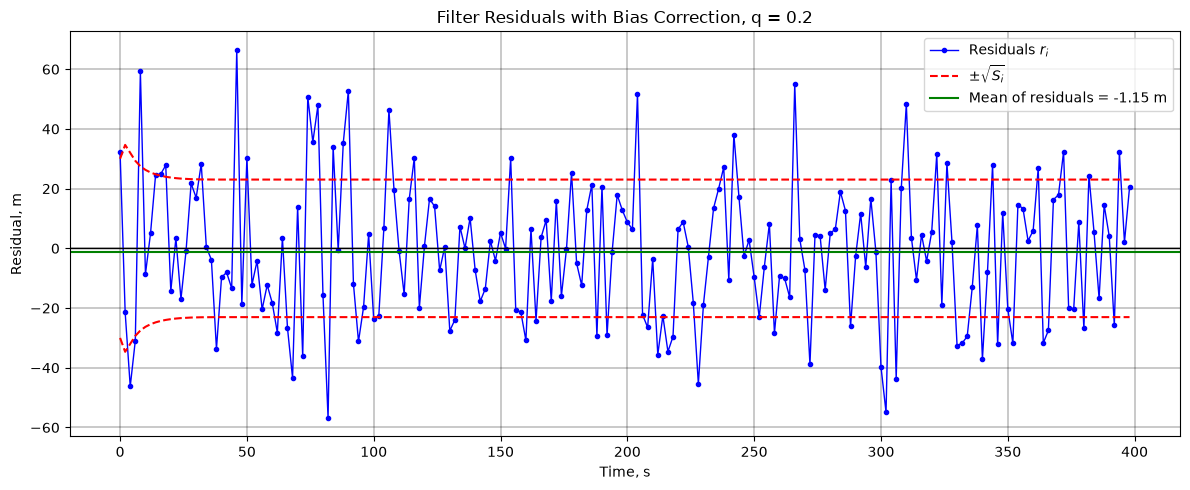

In [12]:
Q_BIAS = 0.2

x_pred_c, P_pred_c, x_filt_c, P_filt_c, K_c, residuals_c, S_c = kalman_filter(
    measured_trajectory_train, PHI, G, H, Q, R, X_0_0, P_0_0, q_bias=Q_BIAS)

print(f"Mean of residuals: {np.mean(residuals_c):.2f} m (without correction: {np.mean(residuals):.2f} m)")
print(f"Residuals inside ±sqrt(S_i): {100 * get_inside_fraction(residuals_c, S_c):.1f}% (without correction: {100 * get_inside_fraction(residuals, S):.1f}%)")

plot_residuals(residuals_c, S_c, f"Filter Residuals with Bias Correction, q = {Q_BIAS}")

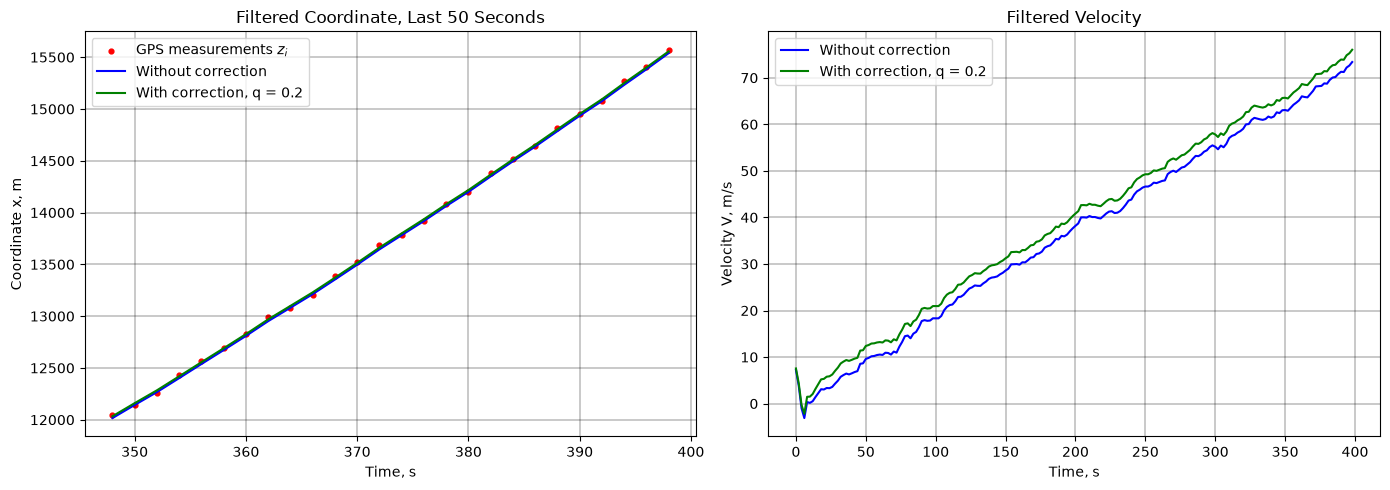

In [13]:
# filtered estimates with and without the bias correction
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(steps[zoom], measured_trajectory_train[zoom], color="red", s=12, label="GPS measurements $z_i$")
axes[0].plot(steps[zoom], x_filt[zoom, 0, 0], color="blue", linewidth=1.5, label="Without correction")
axes[0].plot(steps[zoom], x_filt_c[zoom, 0, 0], color="green", linewidth=1.5, label=f"With correction, q = {Q_BIAS}")
axes[0].set_title("Filtered Coordinate, Last 50 Seconds")
axes[0].set_xlabel("Time, s")
axes[0].set_ylabel("Coordinate x, m")
axes[0].grid(True, color="black", linewidth=0.3)
axes[0].legend(frameon=True)

axes[1].plot(steps, x_filt[:, 1, 0], color="blue", linewidth=1.5, label="Without correction")
axes[1].plot(steps, x_filt_c[:, 1, 0], color="green", linewidth=1.5, label=f"With correction, q = {Q_BIAS}")
axes[1].set_title("Filtered Velocity")
axes[1].set_xlabel("Time, s")
axes[1].set_ylabel("Velocity V, m/s")
axes[1].grid(True, color="black", linewidth=0.3)
axes[1].legend(frameon=True)
fig.tight_layout()
plt.show()

## Step IV. Analyzing the true error when ignoring bias of state noise

In [14]:
# systematic error of the filter that ignores the bias, equations (3) and (4)
mu_pred = np.zeros((SIZE, 2, 1))
mu_filt = np.zeros((SIZE, 2, 1))

identity = np.eye(2)
mu_prev = np.zeros((2, 1))
for i in range(SIZE):
    mu_pred[i] = PHI @ mu_prev + G * Q_BIAS
    mu_filt[i] = (identity - K[i] @ H) @ mu_pred[i]
    mu_prev = mu_filt[i]

# true full error = random error (from P) + systematic error (from mu)
true_error_x = np.sqrt(P_filt[:, 0, 0] + mu_filt[:, 0, 0]**2)
true_error_v = np.sqrt(P_filt[:, 1, 1] + mu_filt[:, 1, 0]**2)
sigma_x_filt = np.sqrt(P_filt[:, 0, 0])
sigma_v_filt = np.sqrt(P_filt[:, 1, 1])

print(f"Coordinate: filter error from P = {sigma_x_filt[-1]:.2f} m, systematic error = {mu_filt[-1, 0, 0]:.2f} m, true error = {true_error_x[-1]:.2f} m")
print(f"Velocity: filter error from P = {sigma_v_filt[-1]:.2f} m/s, systematic error = {mu_filt[-1, 1, 0]:.2f} m/s, true error = {true_error_v[-1]:.2f} m/s")
print(f"Measurement error sigma_eta = {SIGMA_ETA:.2f} m")

Coordinate: filter error from P = 9.92 m, systematic error = 17.36 m, true error = 20.00 m
Velocity: filter error from P = 1.03 m/s, systematic error = 2.64 m/s, true error = 2.83 m/s
Measurement error sigma_eta = 20.00 m


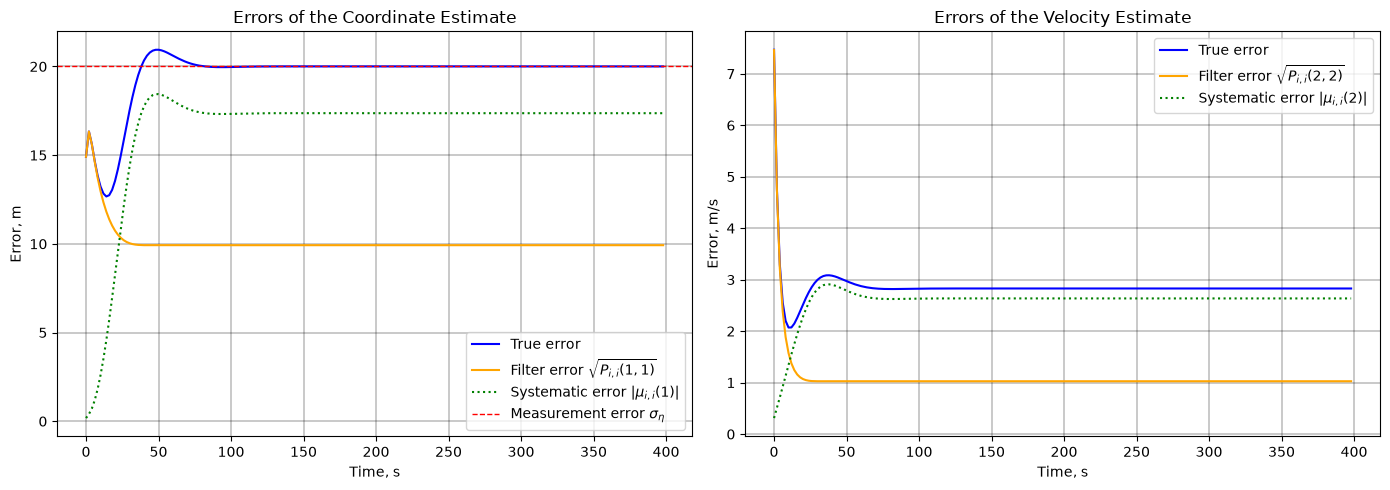

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(steps, true_error_x, color="blue", linewidth=1.5, label="True error")
axes[0].plot(steps, sigma_x_filt, color="orange", linewidth=1.5, label="Filter error $\\sqrt{P_{i,i}(1,1)}$")
axes[0].plot(steps, np.abs(mu_filt[:, 0, 0]), color="green", linestyle=":", linewidth=1.5, label="Systematic error $|\\mu_{i,i}(1)|$")
axes[0].axhline(SIGMA_ETA, color="red", linestyle="--", linewidth=1, label="Measurement error $\\sigma_\\eta$")
axes[0].set_title("Errors of the Coordinate Estimate")
axes[0].set_xlabel("Time, s")
axes[0].set_ylabel("Error, m")
axes[0].grid(True, color="black", linewidth=0.3)
axes[0].legend(frameon=True)

axes[1].plot(steps, true_error_v, color="blue", linewidth=1.5, label="True error")
axes[1].plot(steps, sigma_v_filt, color="orange", linewidth=1.5, label="Filter error $\\sqrt{P_{i,i}(2,2)}$")
axes[1].plot(steps, np.abs(mu_filt[:, 1, 0]), color="green", linestyle=":", linewidth=1.5, label="Systematic error $|\\mu_{i,i}(2)|$")
axes[1].set_title("Errors of the Velocity Estimate")
axes[1].set_xlabel("Time, s")
axes[1].set_ylabel("Error, m/s")
axes[1].grid(True, color="black", linewidth=0.3)
axes[1].legend(frameon=True)
fig.tight_layout()
plt.show()